# Model Comparison

Utilities to compare fitted models per participant (AIC/BIC) and visualize winning-model distributions by group:
- odd participant ID: interleaved
- even participant ID: blocked


In [22]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [23]:
EXCLUDED_PARTICIPANTS = {107, 109}

def participant_group(pid):
    pid = int(pid)
    if 1 <= pid <= 60:
        return 'interleaved' if (pid % 2 == 1) else 'blocked'
    if 61 <= pid <= 90:
        return 'blocked2'
    if 91 <= pid <= 125:
        return 'blocked3'
    return 'other'

def resolve_model_fits_dir(base_dir=None):
    candidates = []
    if base_dir is not None:
        candidates.append(Path(base_dir))
    candidates.extend([Path('model_fits'), Path('../model_fits')])
    for c in candidates:
        if c.exists():
            return c
    raise FileNotFoundError('Could not find model_fits directory (tried model_fits and ../model_fits).')

def load_best_seed_summary(base_dir=None):
    base = resolve_model_fits_dir(base_dir)
    summary_path = base / 'best_seed_summary.csv'
    if summary_path.exists():
        return pd.read_csv(summary_path)
    return None

def resolve_result_path(model_name, pid, base_dir=None, best_seed_summary=None):
    base = resolve_model_fits_dir(base_dir)
    pid = int(pid)
    participant_dir = base / model_name / str(pid)
    legacy_path = participant_dir / 'results.json'
    if legacy_path.exists():
        return legacy_path

    summary = best_seed_summary if best_seed_summary is not None else load_best_seed_summary(base)
    if summary is not None and not summary.empty:
        subset = summary[(summary['model'] == model_name) & (summary['participant_id'].astype(int) == pid)]
        if not subset.empty:
            summary_path = Path(subset.iloc[0]['results_path'])
            if summary_path.exists():
                return summary_path

    seed_paths = sorted(participant_dir.glob('seed_*/results.json'))
    if not seed_paths:
        raise FileNotFoundError(f'No results found for model={model_name}, participant={pid}')

    best_path = None
    best_loglik = -np.inf
    for path in seed_paths:
        with open(path, 'r', encoding='utf-8') as f:
            res = json.load(f)
        loglik = res.get('metrics', {}).get('loglik', -np.inf)
        if loglik > best_loglik:
            best_loglik = loglik
            best_path = path

    if best_path is None:
        raise FileNotFoundError(f'No usable seeded results found for model={model_name}, participant={pid}')
    return best_path

def load_result(model_name, pid, base_dir=None, best_seed_summary=None):
    path = resolve_result_path(model_name, pid, base_dir=base_dir, best_seed_summary=best_seed_summary)
    with open(path, 'r', encoding='utf-8') as f:
        return json.load(f)

def load_model_fit_results(base_dir=None):
    """Load one best result per model and participant from the seeded model_fits tree."""
    base = resolve_model_fits_dir(base_dir)
    best_seed_summary = load_best_seed_summary(base)

    rows = []
    for model_dir in sorted([d for d in base.iterdir() if d.is_dir()]):
        model_name = model_dir.name
        participant_dirs = [d for d in model_dir.iterdir() if d.is_dir() and d.name.isdigit()]
        for pid_dir in sorted(participant_dirs, key=lambda x: int(x.name)):
            res = load_result(model_name, int(pid_dir.name), base_dir=base, best_seed_summary=best_seed_summary)

            pid = int(res.get('participant_id', pid_dir.name))
            if pid in EXCLUDED_PARTICIPANTS:
                continue

            metrics = res.get('metrics', {})
            row = {
                'participant_id': pid,
                'group': participant_group(pid),
                'model': model_name,
                'AIC': metrics.get('AIC', np.nan),
                'BIC': metrics.get('BIC', np.nan),
                'loglik': metrics.get('loglik', np.nan),
                'seed': res.get('seed', np.nan),
            }
            rows.append(row)

    if not rows:
        raise ValueError(f'No results found under {base.resolve()}')

    df = pd.DataFrame(rows).sort_values(['participant_id', 'model']).reset_index(drop=True)
    return df


In [24]:
def compare_models_per_participant(df, criterion='AIC'):
    """Return one winning model per participant by minimizing criterion (AIC or BIC)."""
    crit = criterion.upper()
    if crit not in {'AIC', 'BIC'}:
        raise ValueError("criterion must be 'AIC' or 'BIC'")

    needed = {'participant_id', 'group', 'model', crit}
    missing = needed - set(df.columns)
    if missing:
        raise ValueError(f'Missing required columns: {sorted(missing)}')

    tmp = df.dropna(subset=[crit]).copy()
    idx = tmp.groupby('participant_id')[crit].idxmin()
    winners = tmp.loc[idx].sort_values('participant_id').reset_index(drop=True)
    winners = winners.rename(columns={crit: 'winning_value'})
    winners['criterion'] = crit
    return winners[['participant_id', 'group', 'model', 'criterion', 'winning_value']]


In [25]:
def plot_winning_model_histograms(winners_df, criterion='AIC', model_order=None, model_name_map=None):
    """Plot winner-count histograms split by group (interleaved, blocked, blocked2, blocked3)."""
    crit = criterion.upper()
    data = winners_df.copy()
    if model_name_map is None:
        model_name_map = {}

    data['model_label'] = data['model'].map(lambda m: model_name_map.get(m, m))

    if model_order is None:
        model_order = sorted(data['model'].unique())
    model_order_labels = [model_name_map.get(m, m) for m in model_order]

    # Color by model family
    color_by_model = {}
    for m in model_order:
        if m.startswith('wm_'):
            color_by_model[m] = '#E69F00'  # WM
        else:
            color_by_model[m] = '#0072B2'  # GMM
    bar_colors = [color_by_model[m] for m in model_order]

    groups = [
        ('interleaved', 'Interleaved (odd IDs 1-60)'),
        ('blocked', 'Blocked (even IDs 1-60)'),
        ('blocked2', 'Blocked2 (IDs 61-90)'),
        ('blocked3', 'Blocked3 (IDs 91-125; excluding 107, 109)'),
    ]
    ncols = len(groups)
    fig, axes = plt.subplots(1, ncols, figsize=(6 * ncols, 4), sharey=True)
    if ncols == 1:
        axes = [axes]

    for ax, (group_key, group_title) in zip(axes, groups):
        subset = data[data['group'] == group_key]
        counts = subset['model_label'].value_counts()
        heights = [int(counts.get(lbl, 0)) for lbl in model_order_labels]

        ax.bar(model_order_labels, heights, color=bar_colors)
        ax.set_title(f'{group_title} - Winners by {crit}')
        ax.set_xlabel('Winning model')
        ax.set_ylabel('Count')
        ax.tick_params(axis='x', rotation=25)

    from matplotlib.patches import Patch
    legend_handles = [
        Patch(facecolor='#0072B2', label='GMM models'),
        Patch(facecolor='#E69F00', label='WM models'),
    ]
    axes[-1].legend(handles=legend_handles, loc='upper right')

    plt.tight_layout()
    plt.show()


,participant_id,group,model,criterion,winning_value
0,1,interleaved,gmm_no_forgetting_tied_lrs,AIC,255.259705
1,2,blocked,wm_last_m_category_specific,AIC,453.478898
2,3,interleaved,wm_exponential_decay,AIC,197.669672
3,4,blocked,wm_exponential_decay,AIC,355.460691
4,5,interleaved,gmm_no_forgetting_tied_lrs,AIC,539.216309


,participant_id,group,model,criterion,winning_value
0,1,interleaved,gmm_no_forgetting_tied_lrs,BIC,291.833771
1,2,blocked,wm_last_m_category_specific,BIC,465.585343
2,3,interleaved,wm_exponential_decay,BIC,205.806523
3,4,blocked,wm_exponential_decay,BIC,363.560158
4,5,interleaved,wm_exponential_decay,BIC,562.186933


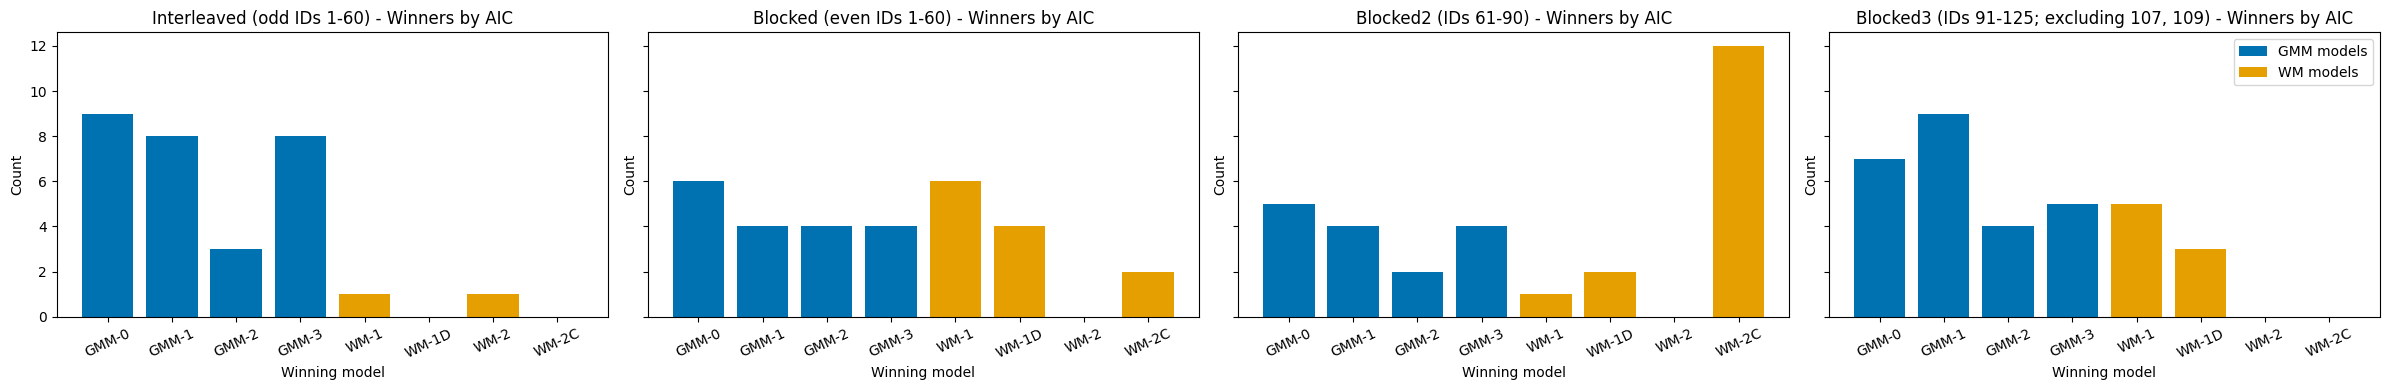

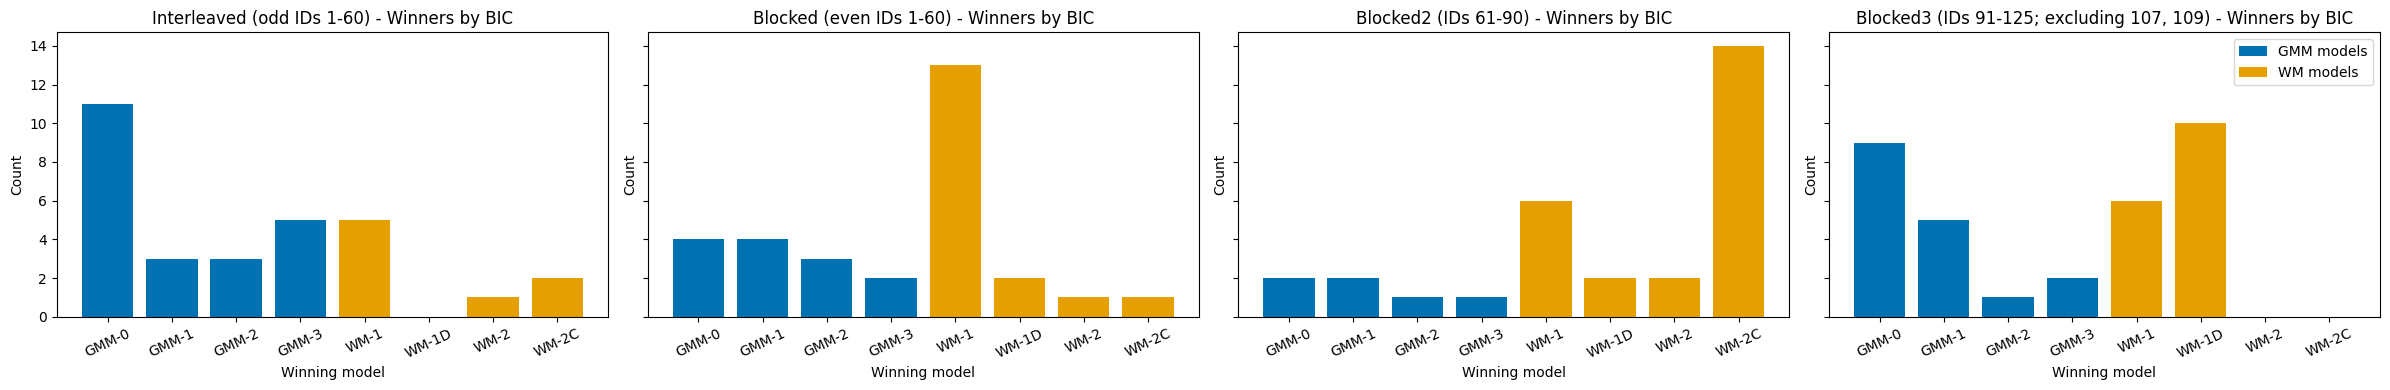

In [26]:
# Example usage
df = load_model_fit_results('../model_fits')

preferred_order = [
    'gmm_no_forgetting_no_lr',
    'gmm_no_forgetting_tied_lrs',
    'gmm_forgetting_no_lr',
    'gmm_forgetting_tied_lrs',
    'wm_exponential_decay',
    'wm_exponential_decay_dual',
    'wm_last_m',
    'wm_last_m_category_specific',
]

# Keep preferred order but only for models present in current results
model_order = [m for m in preferred_order if m in set(df['model'].unique())]

pretty = {
    'gmm_no_forgetting_no_lr': 'GMM-0',
    'gmm_no_forgetting_tied_lrs': 'GMM-1',
    'gmm_forgetting_no_lr': 'GMM-2',
    'gmm_forgetting_tied_lrs': 'GMM-3',
    'wm_exponential_decay': 'WM-1',
    'wm_exponential_decay_dual': 'WM-1D',
    'wm_last_m': 'WM-2',
    'wm_last_m_category_specific': 'WM-2C',
}

winners_aic = compare_models_per_participant(df, criterion='AIC')
winners_bic = compare_models_per_participant(df, criterion='BIC')

display(winners_aic.head())
display(winners_bic.head())

plot_winning_model_histograms(winners_aic, criterion='AIC', model_order=model_order, model_name_map=pretty)
plot_winning_model_histograms(winners_bic, criterion='BIC', model_order=model_order, model_name_map=pretty)


In [27]:
# Optional summary tables
def winner_table(winners_df):
    return winners_df.groupby(['group', 'model']).size().rename('n').reset_index().sort_values(['group', 'n'], ascending=[True, False])

display(winner_table(winners_aic))
display(winner_table(winners_bic))


,group,model,n
2,blocked,gmm_no_forgetting_no_lr,6
4,blocked,wm_exponential_decay,6
0,blocked,gmm_forgetting_no_lr,4
1,blocked,gmm_forgetting_tied_lrs,4
3,blocked,gmm_no_forgetting_tied_lrs,4
5,blocked,wm_exponential_decay_dual,4
6,blocked,wm_last_m_category_specific,2
13,blocked2,wm_last_m_category_specific,12
9,blocked2,gmm_no_forgetting_no_lr,5
8,blocked2,gmm_forgetting_tied_lrs,4


,group,model,n
4,blocked,wm_exponential_decay,13
2,blocked,gmm_no_forgetting_no_lr,4
3,blocked,gmm_no_forgetting_tied_lrs,4
0,blocked,gmm_forgetting_no_lr,3
1,blocked,gmm_forgetting_tied_lrs,2
5,blocked,wm_exponential_decay_dual,2
6,blocked,wm_last_m,1
7,blocked,wm_last_m_category_specific,1
15,blocked2,wm_last_m_category_specific,14
12,blocked2,wm_exponential_decay,6


,participant_id,group,model,rho
0,6,blocked,gmm_forgetting_tied_lrs,0.958159
1,11,interleaved,gmm_forgetting_tied_lrs,0.999964
2,14,blocked,gmm_forgetting_no_lr,0.160327
3,16,blocked,gmm_forgetting_tied_lrs,0.965777
4,17,interleaved,gmm_forgetting_no_lr,0.865663


N interleaved: 11
N blocked: 8
N blocked2: 6
N blocked3: 9


C:\Users\franc\AppData\Local\Temp\ipykernel_64860\3525433078.py:35: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(vals, labels=labels, patch_artist=True, showfliers=False)


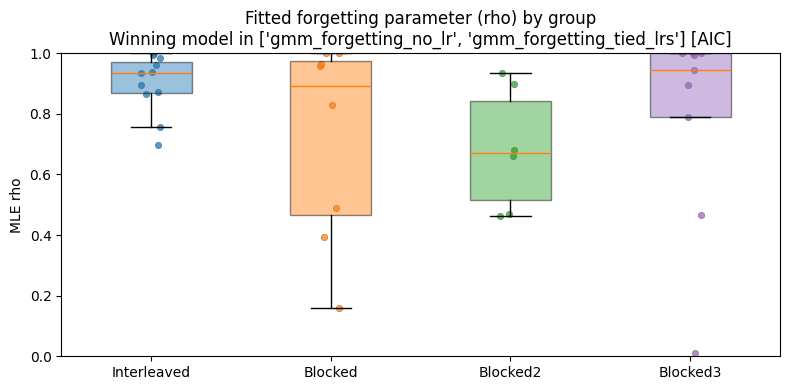

In [28]:
# Forgetting-parameter comparison for participants whose winning model is one of:
# gmm_forgetting_no_lr or gmm_forgetting_tied_lrs
comparison_criterion = 'AIC'  # change to 'BIC' if needed

winners = compare_models_per_participant(df, criterion=comparison_criterion)
target_models = {'gmm_forgetting_no_lr', 'gmm_forgetting_tied_lrs'}
sel = winners[winners['model'].isin(target_models)].copy()

def load_theta_hat(model_name, pid, base_dir=None):
    return load_result(model_name, pid, base_dir=base_dir).get('theta_hat', {})

rows = []
for _, r in sel.iterrows():
    th = load_theta_hat(r['model'], r['participant_id'])
    rows.append({
        'participant_id': int(r['participant_id']),
        'group': r['group'],
        'model': r['model'],
        'rho': th.get('rho', np.nan),
    })

rho_df = pd.DataFrame(rows).dropna(subset=['rho']).copy()
display(rho_df.head())
for g in ['interleaved', 'blocked', 'blocked2', 'blocked3']:
    print(f'N {g}:', int((rho_df['group'] == g).sum()))

groups = ['interleaved', 'blocked', 'blocked2', 'blocked3']
labels = ['Interleaved', 'Blocked', 'Blocked2', 'Blocked3']
vals = [rho_df.loc[rho_df['group'] == g, 'rho'].to_numpy(dtype=float) for g in groups]

fig, ax = plt.subplots(figsize=(8, 4))
bp = ax.boxplot(vals, labels=labels, patch_artist=True, showfliers=False)
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#9467bd']
for box, c in zip(bp['boxes'], colors):
    box.set_facecolor(c)
    box.set_alpha(0.45)

rng = np.random.default_rng(0)
for i, y in enumerate(vals, start=1):
    x = i + rng.uniform(-0.06, 0.06, size=len(y))
    ax.scatter(x, y, s=22, alpha=0.75, color=colors[i-1], edgecolors='k', linewidths=0.2)

ax.set_title(f'Fitted forgetting parameter (rho) by group\nWinning model in {sorted(target_models)} [{comparison_criterion}]')
ax.set_ylabel('MLE rho')
ax.set_ylim(0.0, 1.0)
plt.tight_layout()
plt.show()


,participant_id,group,model,exp_train,exp_test,part_train,part_test
0,1,interleaved,gmm_no_forgetting_tied_lrs,0.829432,0.885839,0.842697,0.908730
1,2,blocked,wm_last_m_category_specific,0.840602,0.544846,0.869318,0.636364
2,3,interleaved,wm_exponential_decay,0.944663,0.766863,0.977778,0.900794
3,4,blocked,wm_exponential_decay,0.904909,0.596638,0.915730,0.699187
4,5,interleaved,gmm_no_forgetting_tied_lrs,0.649522,0.687371,0.644444,0.697211


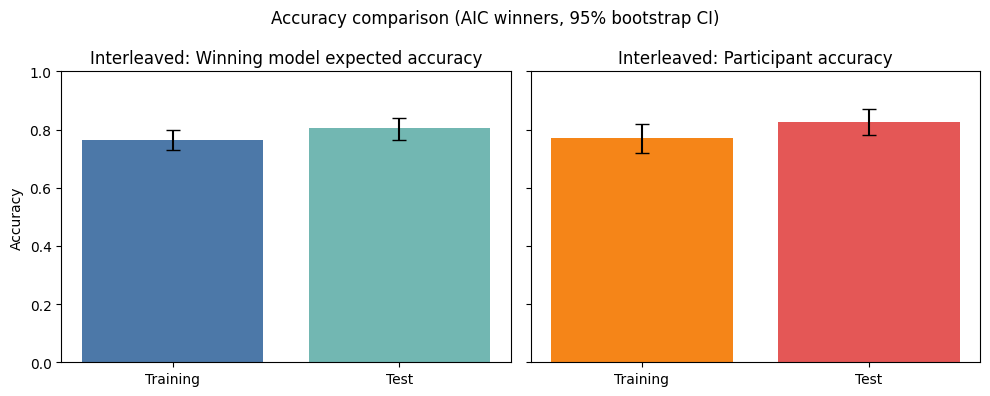

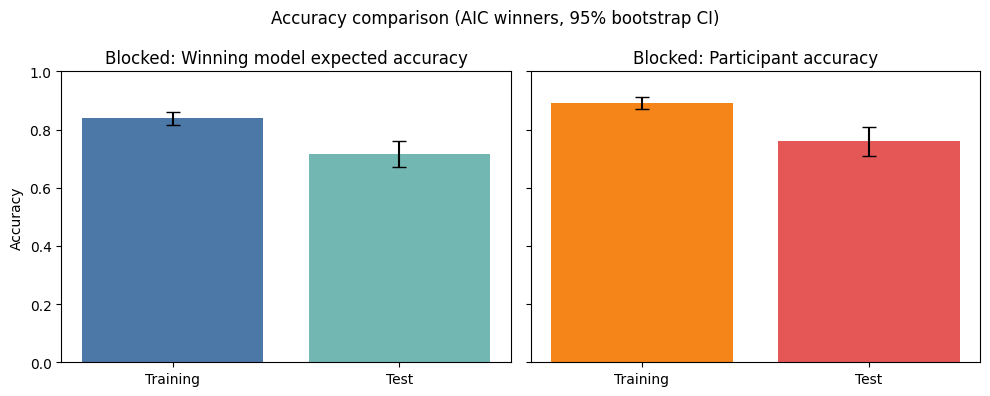

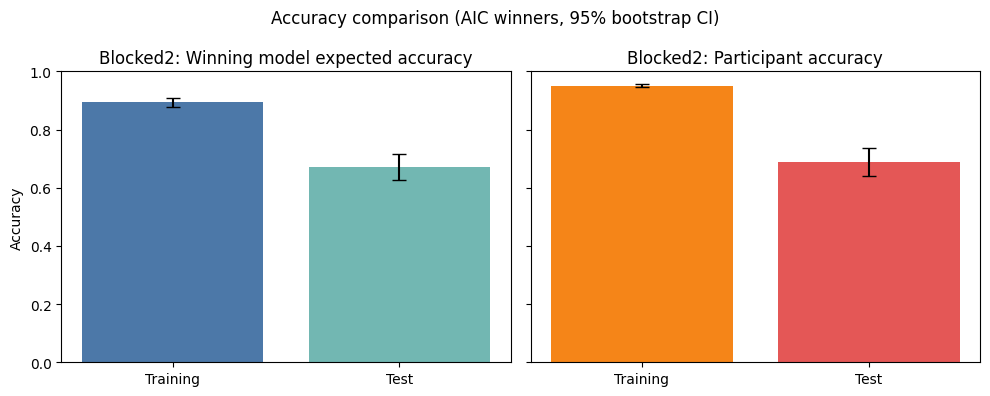

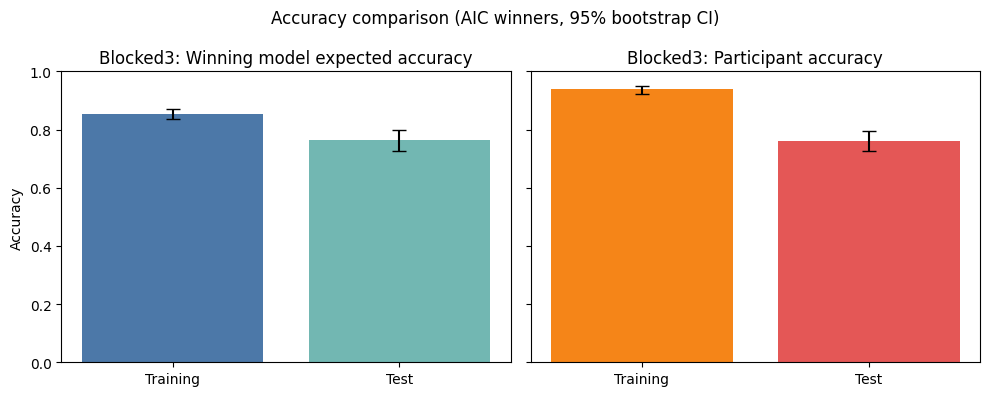

In [29]:
# Winning-model expected accuracy vs participant accuracy (bootstrap 95% CI)
comparison_criterion = 'AIC'  # or 'BIC'
n_boot = 5000
rng = np.random.default_rng(123)

def bootstrap_mean_ci(x, n_boot=5000, alpha=0.05, rng=None):
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    if x.size == 0:
        return np.nan, np.nan, np.nan
    if rng is None:
        rng = np.random.default_rng(0)
    idx = rng.integers(0, x.size, size=(n_boot, x.size))
    means = x[idx].mean(axis=1)
    m = float(x.mean())
    lo = float(np.quantile(means, alpha/2))
    hi = float(np.quantile(means, 1-alpha/2))
    return m, lo, hi

winners = compare_models_per_participant(df, criterion=comparison_criterion)

rows = []
for _, w in winners.iterrows():
    res = load_result(w['model'], w['participant_id'])
    ea = res.get('expected_accuracy', {})
    pa = res.get('participant_accuracy', {})
    rows.append({
        'participant_id': int(w['participant_id']),
        'group': w['group'],
        'model': w['model'],
        'exp_train': ea.get('training', np.nan),
        'exp_test': ea.get('test', np.nan),
        'part_train': pa.get('training', np.nan),
        'part_test': pa.get('test', np.nan),
    })

acc_df = pd.DataFrame(rows)
display(acc_df.head())

for group in ['interleaved', 'blocked', 'blocked2', 'blocked3']:
    sub = acc_df[acc_df['group'] == group].copy()

    em_tr, el_tr, eh_tr = bootstrap_mean_ci(sub['exp_train'].to_numpy(), n_boot=n_boot, rng=rng)
    em_te, el_te, eh_te = bootstrap_mean_ci(sub['exp_test'].to_numpy(), n_boot=n_boot, rng=rng)

    pm_tr, pl_tr, ph_tr = bootstrap_mean_ci(sub['part_train'].to_numpy(), n_boot=n_boot, rng=rng)
    pm_te, pl_te, ph_te = bootstrap_mean_ci(sub['part_test'].to_numpy(), n_boot=n_boot, rng=rng)

    fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

    means_left = [em_tr, em_te]
    yerr_left = [
        [em_tr - el_tr, em_te - el_te],
        [eh_tr - em_tr, eh_te - em_te],
    ]
    axes[0].bar(['Training', 'Test'], means_left, yerr=yerr_left, capsize=5, color=['#4C78A8', '#72B7B2'])
    axes[0].set_title(f'{group.capitalize()}: Winning model expected accuracy')
    axes[0].set_ylabel('Accuracy')
    axes[0].set_ylim(0.0, 1.0)

    means_right = [pm_tr, pm_te]
    yerr_right = [
        [pm_tr - pl_tr, pm_te - pl_te],
        [ph_tr - pm_tr, ph_te - pm_te],
    ]
    axes[1].bar(['Training', 'Test'], means_right, yerr=yerr_right, capsize=5, color=['#F58518', '#E45756'])
    axes[1].set_title(f'{group.capitalize()}: Participant accuracy')
    axes[1].set_ylim(0.0, 1.0)

    fig.suptitle(f'Accuracy comparison ({comparison_criterion} winners, 95% bootstrap CI)')
    plt.tight_layout()
    plt.show()


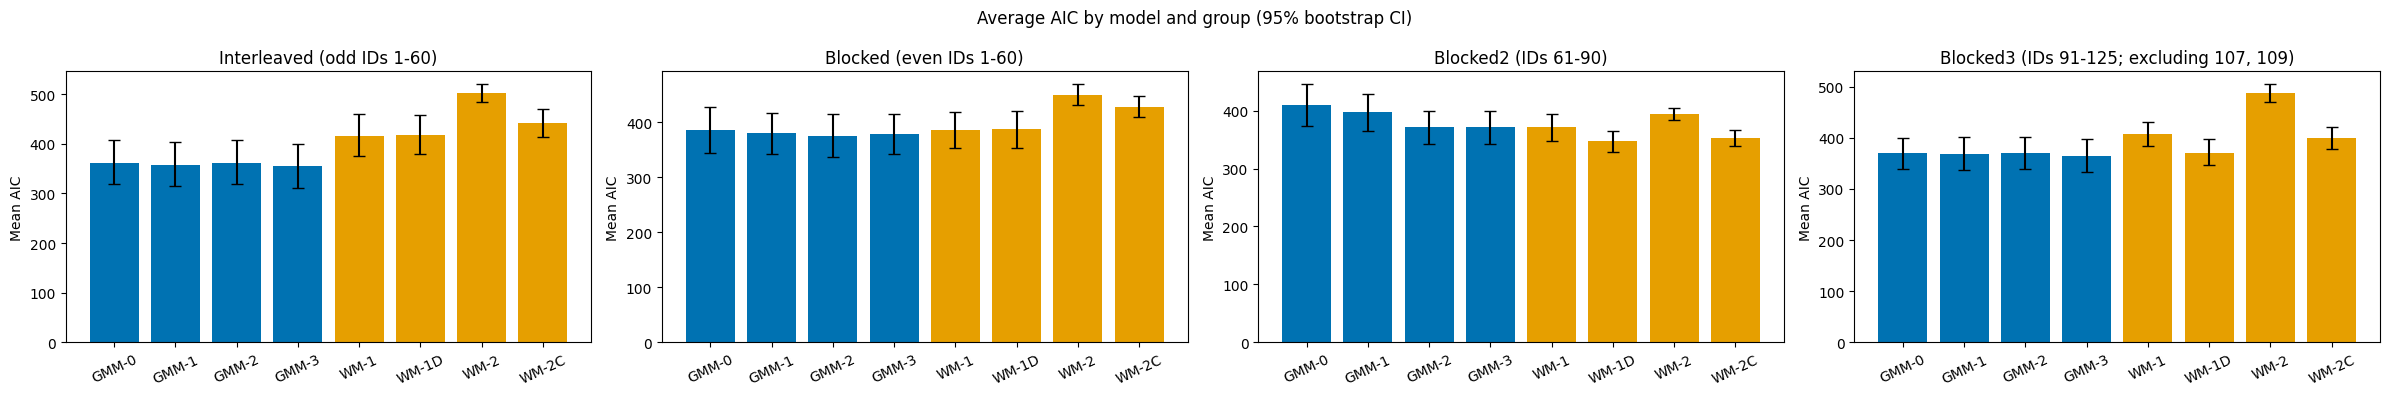

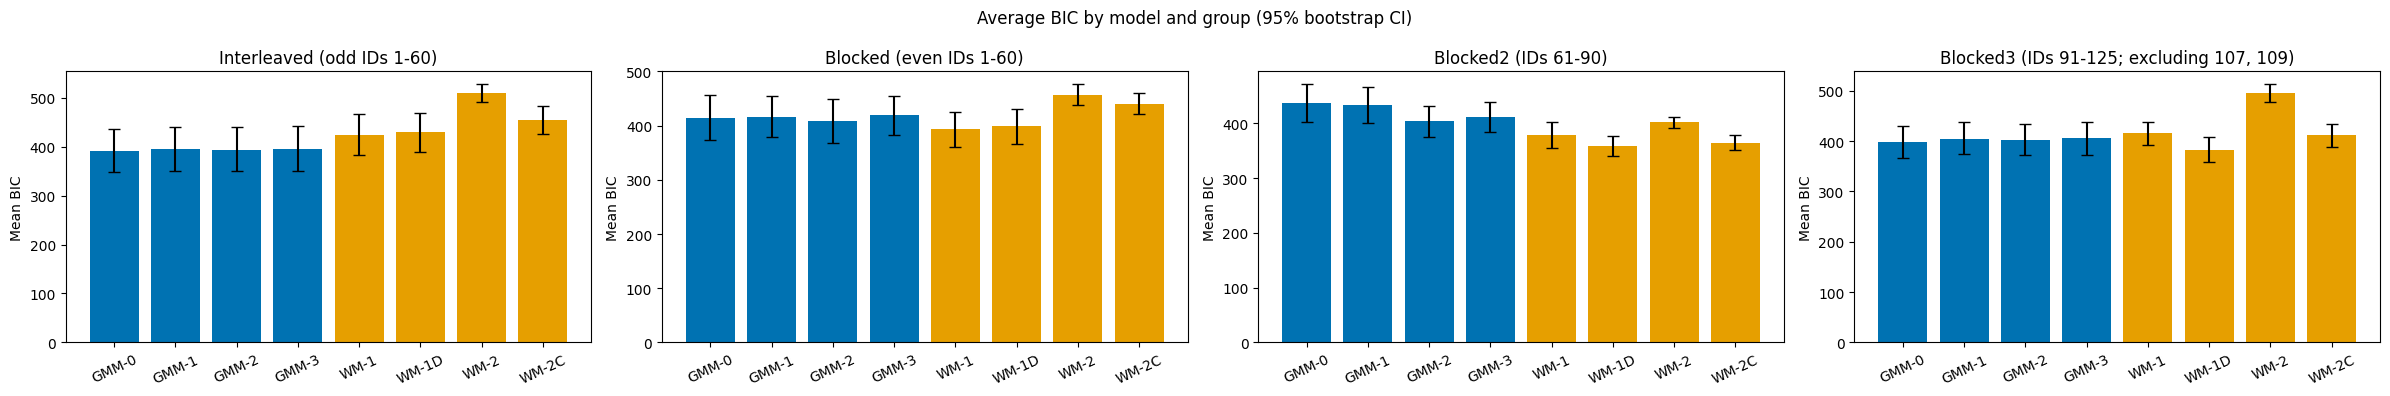

In [30]:
# Average model metric (AIC/BIC) by group with 95% bootstrap CI
n_boot = 5000
rng = np.random.default_rng(42)
groups = ['interleaved', 'blocked', 'blocked2', 'blocked3']
group_titles = {
    'interleaved': 'Interleaved (odd IDs 1-60)',
    'blocked': 'Blocked (even IDs 1-60)',
    'blocked2': 'Blocked2 (IDs 61-90)',
    'blocked3': 'Blocked3 (IDs 91-125; excluding 107, 109)',
}

def bootstrap_mean_ci(x, n_boot=5000, alpha=0.05, rng=None):
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    if x.size == 0:
        return np.nan, np.nan, np.nan
    if rng is None:
        rng = np.random.default_rng(0)
    idx = rng.integers(0, x.size, size=(n_boot, x.size))
    means = x[idx].mean(axis=1)
    m = float(x.mean())
    lo = float(np.quantile(means, alpha/2))
    hi = float(np.quantile(means, 1-alpha/2))
    return m, lo, hi

for metric in ['AIC', 'BIC']:
    fig, axes = plt.subplots(1, 4, figsize=(24, 4), sharey=False)

    for ax, g in zip(axes, groups):
        sub = df[df['group'] == g].copy()
        models_here = model_order if 'model_order' in globals() else sorted(sub['model'].unique())

        means = []
        los = []
        his = []
        labels = []

        for m in models_here:
            vals = sub.loc[sub['model'] == m, metric].to_numpy(dtype=float)
            mu, lo, hi = bootstrap_mean_ci(vals, n_boot=n_boot, rng=rng)
            means.append(mu)
            los.append(mu - lo if np.isfinite(mu) and np.isfinite(lo) else np.nan)
            his.append(hi - mu if np.isfinite(mu) and np.isfinite(hi) else np.nan)
            labels.append(pretty[m] if 'pretty' in globals() and m in pretty else m)

        colors = ['#E69F00' if m.startswith('wm_') else '#0072B2' for m in models_here]
        ax.bar(labels, means, yerr=[los, his], capsize=4, color=colors)
        ax.set_title(f"{group_titles[g]}")
        ax.set_ylabel(f"Mean {metric}")
        ax.tick_params(axis='x', rotation=25)

    fig.suptitle(f"Average {metric} by model and group (95% bootstrap CI)")
    plt.tight_layout()
    plt.show()


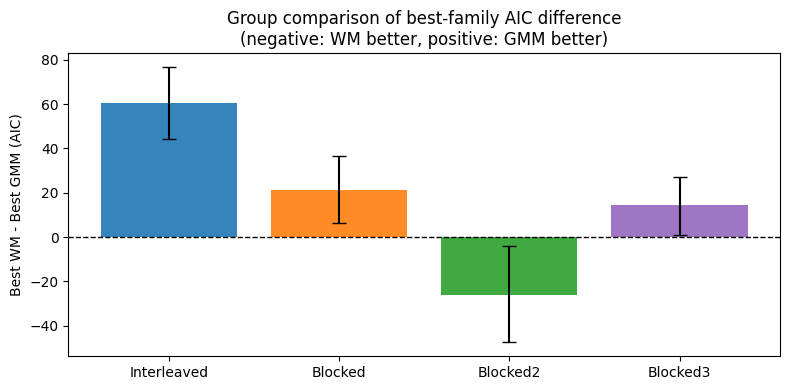

family,participant_id,group,WM,GMM,delta_wm_minus_gmm
0,1,interleaved,374.648376,255.259705,119.388671
1,2,blocked,453.478898,466.270660,-12.791762
2,3,interleaved,197.669672,206.963989,-9.294317
3,4,blocked,355.460691,415.246094,-59.785403
4,5,interleaved,554.054716,539.216309,14.838408


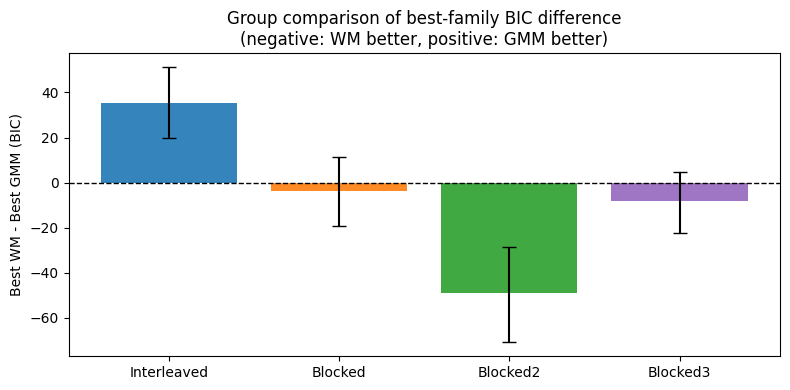

family,participant_id,group,WM,GMM,delta_wm_minus_gmm
0,1,interleaved,382.775946,291.833771,90.942175
1,2,blocked,465.585343,502.589993,-37.004651
2,3,interleaved,205.806523,243.579820,-37.773296
3,4,blocked,363.560158,447.643961,-84.083804
4,5,interleaved,562.186933,575.811281,-13.624349


In [31]:
# Difference between best WM and best GMM per participant, by group
# delta = best_WM_metric - best_GMM_metric (negative favors WM, positive favors GMM)
n_boot = 5000
rng = np.random.default_rng(7)
groups = ['interleaved', 'blocked', 'blocked2', 'blocked3']
group_labels = ['Interleaved', 'Blocked', 'Blocked2', 'Blocked3']

def bootstrap_mean_ci(x, n_boot=5000, alpha=0.05, rng=None):
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    if x.size == 0:
        return np.nan, np.nan, np.nan
    if rng is None:
        rng = np.random.default_rng(0)
    idx = rng.integers(0, x.size, size=(n_boot, x.size))
    means = x[idx].mean(axis=1)
    m = float(x.mean())
    lo = float(np.quantile(means, alpha/2))
    hi = float(np.quantile(means, 1-alpha/2))
    return m, lo, hi

df_cmp = df.copy()
df_cmp['family'] = np.where(df_cmp['model'].str.startswith('wm_'), 'WM', 'GMM')

for metric in ['AIC', 'BIC']:
    fam_best = (
        df_cmp.groupby(['participant_id', 'group', 'family'], as_index=False)[metric]
        .min()
    )

    pivot = fam_best.pivot_table(index=['participant_id', 'group'], columns='family', values=metric).reset_index()
    pivot['delta_wm_minus_gmm'] = pivot['WM'] - pivot['GMM']

    means = []
    yerr_lo = []
    yerr_hi = []

    for g in groups:
        vals = pivot.loc[pivot['group'] == g, 'delta_wm_minus_gmm'].to_numpy(dtype=float)
        mu, lo, hi = bootstrap_mean_ci(vals, n_boot=n_boot, rng=rng)
        means.append(mu)
        yerr_lo.append(mu - lo if np.isfinite(mu) and np.isfinite(lo) else np.nan)
        yerr_hi.append(hi - mu if np.isfinite(mu) and np.isfinite(hi) else np.nan)

    fig, ax = plt.subplots(figsize=(8, 4))
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#9467bd']
    ax.bar(group_labels, means, yerr=[yerr_lo, yerr_hi], capsize=5, color=colors, alpha=0.9)
    ax.axhline(0.0, color='black', linewidth=1, linestyle='--')
    ax.set_ylabel(f'Best WM - Best GMM ({metric})')
    ax.set_title(f'Group comparison of best-family {metric} difference\n(negative: WM better, positive: GMM better)')
    plt.tight_layout()
    plt.show()

    display(pivot[['participant_id', 'group', 'WM', 'GMM', 'delta_wm_minus_gmm']].head())
